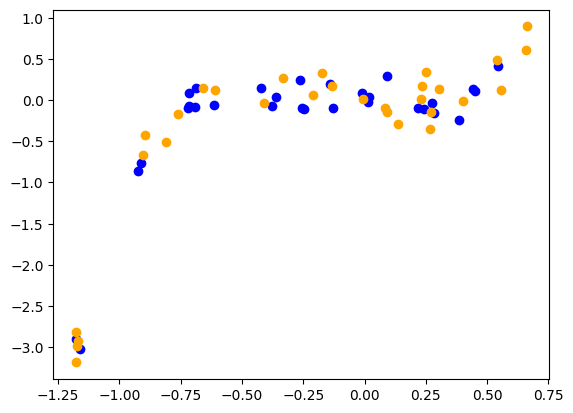

In [4]:
import numpy as np
import matplotlib.pyplot as plt

n = 30
poly_deg = 5

def f(x):
    return 3*np.power(x,poly_deg) + 2*np.power(x,poly_deg-1) + np.random.randn(len(x))/6

x = 2*np.random.rand(n) - 1.25
y = f(x)

x_test = 2*np.random.rand(n) - 1.25
y_test = f(x_test)

plt.scatter(x, y, c='blue')
plt.scatter(x_test,y_test, c='orange')

In [20]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

def make_model(X,Y,deg=2, display=True):
    # Identify the polynomial features
    poly_features = PolynomialFeatures(degree=deg, include_bias=False)
    X_poly = poly_features.fit_transform(X.reshape(-1,1))

    # Create the model
    lin_reg = LinearRegression()
    lin_reg.fit(X_poly, Y)

    if display:
        print(lin_reg.intercept_,lin_reg.coef_)
        plt.scatter(X,y, c='blue')
        plt.scatter(x_test,y_test, c='orange')
        x_line = np.linspace(X.min(), X.max(), 100)
        y_line = lin_reg.intercept_
        for i in range(len(lin_reg.coef_)):
            y_line += lin_reg.coef_[i] * np.power(x_line, i+1)

        plt.plot(x_line,y_line, color='green')
        plt.ylim([y.min()-1, y.max()+1])
        plt.title(f"Polynomial Regression (degree={deg})")
        plt.show()

    return lin_reg.intercept_, lin_reg.coef_

def predict_model(X,Y,intercept,coef):
    y_pred = intercept
    for i in range(len(coef)):
        y_pred += coef[i] * np.power(X,i+1)
    rmse = np.sqrt(np.sum((y_pred - Y)**2) / len(Y))
    # print(f"RMSE = {rmse}")
    return rmse

0.3201852569409842 [-0.23453109 -2.01365724]


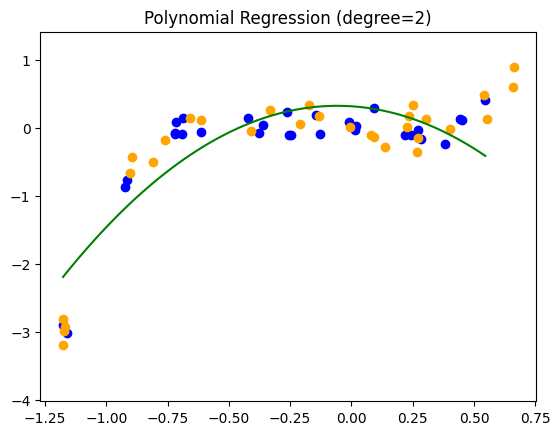

np.float64(0.5952630067992712)

In [21]:
#######  Quadratic Regression (power of 2)  ##########
int,coef = make_model(x,y,2)
predict_model(x_test,y_test,int,coef)

-0.06438772408736668 [-0.76050677  1.20242252  3.33282639]


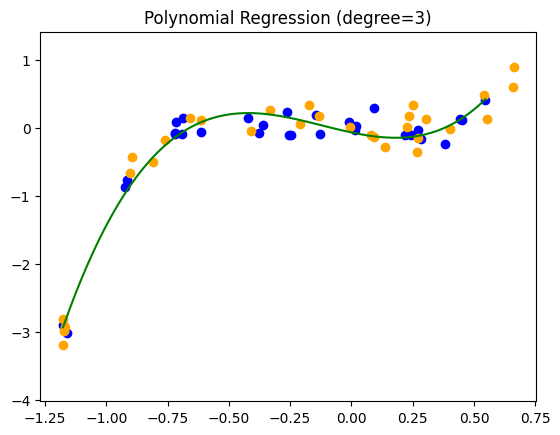

np.float64(0.1939224114532137)

In [22]:
#######  Cubic Regression (power of 3)  ##########
int,coef = make_model(x,y,3)
predict_model(x_test,y_test,int,coef)

Power of 4:
-0.056612766739685044 [-0.30047817  1.27296413  1.34173185 -1.51334276]


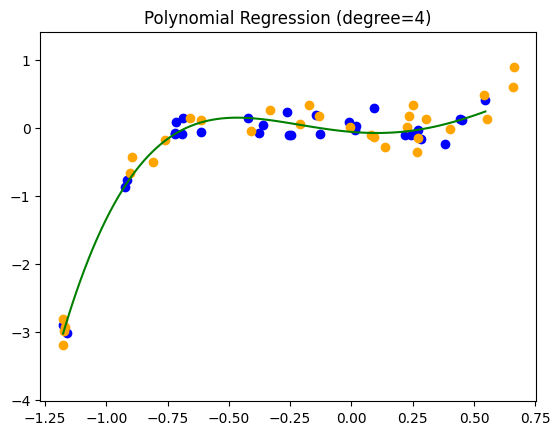

RMSE: 0.19502805336888973
Power of 5:
0.008894267280467077 [-0.40288031 -0.28925171  1.37892352  3.23954497  3.16263574]


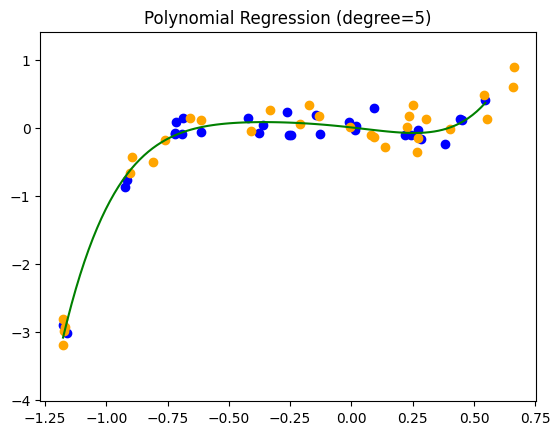

RMSE: 0.1877738703771952
Power of 10:
0.07988125620237455 [ 9.15364351e-01 -3.83408541e-01 -2.63433154e+01 -4.12002036e+01
  1.37707906e+02  3.43089563e+02 -2.26692580e+01 -6.13752713e+02
 -5.44581476e+02 -1.44548978e+02]


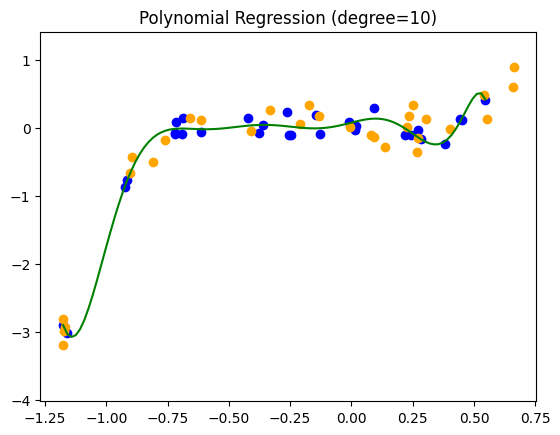

RMSE: 2.2315878348413274
Power of 15:
0.049380528058141665 [ 1.47353626e+00  7.42086845e+00 -6.10015414e+01 -3.33289076e+02
  7.07694414e+02  4.66021400e+03 -2.18256487e+03 -3.01230937e+04
 -1.47892934e+04  8.64013091e+04  1.10544339e+05 -5.07691102e+04
 -1.78946037e+05 -1.22783380e+05 -2.82143649e+04]


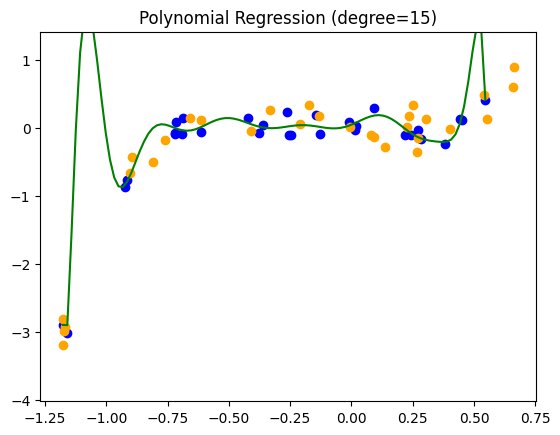

RMSE: 60.750131951915776
Power of 20:
0.023216776671366263 [ 2.50551932e-01  4.06618959e+01  1.22584408e+02 -2.95150413e+03
 -8.13151812e+03  7.67364364e+04  2.08213588e+05 -9.45056360e+05
 -2.79848962e+06  5.64432166e+06  2.10310167e+07 -1.18571202e+07
 -8.64542333e+07 -3.05890750e+07  1.69188498e+08  1.84156232e+08
 -6.96047532e+07 -2.26192746e+08 -1.41059161e+08 -2.97877165e+07]


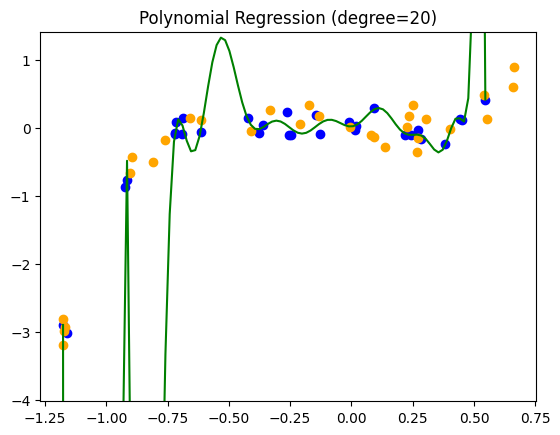

RMSE: 4212.84052132427


In [23]:
#######  Regression with power of k  ##########
k = [4, 5, 10, 15, 20]

for i in k:
    print(f"Power of {i}:")
    int,coef = make_model(x,y,i)
    print(f"RMSE: {predict_model(x_test,y_test,int,coef)}")

In [ ]:
int,coef = make_model(x,y,8)
predict_model(x_test,y_test,int,coef)

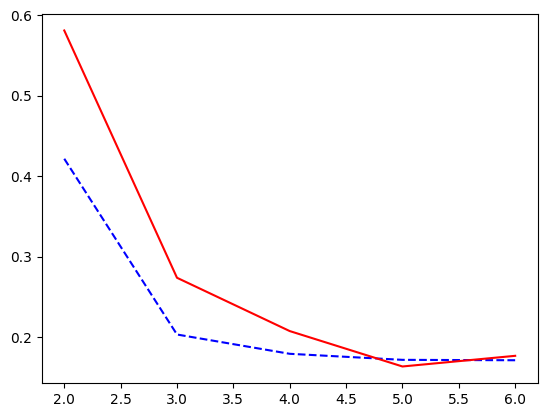

In [162]:
rmse_train = []
rmse_test = []
highest_power = 7

for i in np.arange(2,highest_power):
    int,coef = make_model(x,y,i, display=False)
    rmse_train.append(predict_model(x,y,int,coef))    
    rmse_test.append(predict_model(x_test,y_test,int,coef))

plt.plot(np.arange(2,highest_power), rmse_train, color='blue', linestyle='dashed', label='Train RMSE')
plt.plot(np.arange(2,highest_power), rmse_test, color='red', label='Test RMSE')
plt.show()